# Training analysis

Plots the per-generation log that `training.py` appends to `runs/training_log.csv`.
Every run adds to the same file, so the charts number generations across all runs,
and a dashed line marks where each run started.

Re-run all cells while training is going to see the latest generations.

In [14]:
from pathlib import Path
import math
import matplotlib.pyplot as plt
import pandas as pd

LOG_PATH = Path("runs/training_log.csv")
# Evaluation is 100 games per generation (only ~10 in early runs), so the
# win-rate lines pool this many generations to smooth the noise
ROLLING = 5

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
NEUTRAL = "#b4b2a9"  # draws, and the reference lines a loss can't go below
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": AXIS, "axes.labelcolor": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2,
    "legend.frameon": False, "legend.labelcolor": INK_2,
})

In [15]:
log = pd.read_csv(LOG_PATH)
log["step"] = range(1, len(log) + 1)  # generation number across all runs
run_starts = log.groupby("run", sort=False)["step"].min()

eval_games = {side: log[[f"eval_{side}_wins", f"eval_{side}_draws", f"eval_{side}_losses"]].sum(axis=1) for side in "xo"}
log["eval_wins"] = log.eval_x_wins + log.eval_o_wins
log["eval_draws"] = log.eval_x_draws + log.eval_o_draws
log["eval_losses"] = log.eval_x_losses + log.eval_o_losses
log["eval_games"] = eval_games["x"] + eval_games["o"]

def rolling_rate(wins, games):
    # Wins over games, pooled across the last ROLLING generations
    return wins.rolling(ROLLING, min_periods=1).sum() / games.rolling(ROLLING, min_periods=1).sum()

log["win_rate"] = log.eval_wins / log.eval_games
log["win_rate_rolling"] = rolling_rate(log.eval_wins, log.eval_games)
log["win_rate_x_rolling"] = rolling_rate(log.eval_x_wins, eval_games["x"])
log["win_rate_o_rolling"] = rolling_rate(log.eval_o_wins, eval_games["o"])
log["game_length"] = log.selfplay_positions / log.selfplay_games
log["generation_seconds"] = log.selfplay_seconds + log.train_seconds + log.eval_seconds

print(f"{len(log)} generations over {len(run_starts)} runs, "
      f"{log.selfplay_games.sum():,} self-play games, {log.generation_seconds.sum() / 3600:.1f} h of training")

# The settings can change between runs; the charts mark each run's start with a dashed line
log.groupby("run", sort=False).agg(
    first_generation=("step", "min"), generations=("step", "size"), workers=("workers", "first"),
    sims_per_move=("n_games_simulate", "first"), mct_iterations=("mct_iterations", "first"),
    games_per_generation=("selfplay_games", "first"), eval_games=("eval_games", "first"))

16 generations over 1 runs, 1,600 self-play games, 0.2 h of training


,first_generation,generations,workers,sims_per_move,mct_iterations,games_per_generation,eval_games
run,,,,,,,
2026-11-02 11:27:47,1,16,12,50,200,100,10


In [16]:
def mark_runs(ax):
    # A dashed line at the start of every run after the first
    for step in run_starts[run_starts > 1]:
        ax.axvline(step - 0.5, color=AXIS, linestyle="--", linewidth=1, zorder=0)
    ax.set_xlabel("Generation (all runs)")
    ax.set_xlim(0.5, len(log) + 0.5)

def end_label(ax, series, text, color):
    # Names a line at its last point, so it isn't identified by colour alone
    ax.annotate(text, (log.step.iloc[-1], series.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_2,
                bbox=dict(boxstyle="square,pad=0.1", fc="#fcfcfb", ec="none"))

def percent_axis(ax):
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

## Win rate against plain MCT

The headline question: is the network beating MCT with random playouts? Dots are
single generations; lines pool the last few generations. With 100 evaluation games
per generation a single generation's dot can still swing ~10 points either way (early
runs played only ~10, which swing 20 or more). The MCT opponent's strength is in
`mct_iterations`, so compare win rates within a run.

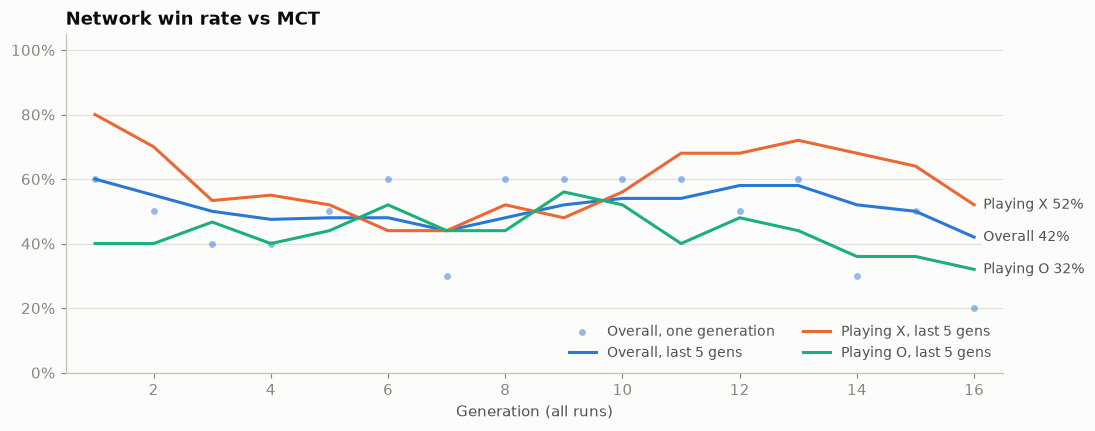

In [17]:
fig, ax = plt.subplots()
ax.scatter(log.step, log.win_rate, s=20, color=BLUE, alpha=0.5, linewidths=0, label="Overall, one generation")
for column, color, label in [("win_rate_rolling", BLUE, "Overall"),
                             ("win_rate_x_rolling", ORANGE, "Playing X"),
                             ("win_rate_o_rolling", AQUA, "Playing O")]:
    ax.plot(log.step, log[column], color=color, label=f"{label}, last {ROLLING} gens")
    end_label(ax, log[column], f"{label} {log[column].iloc[-1]:.0%}", color)
percent_axis(ax)
mark_runs(ax)
ax.set_title("Network win rate vs MCT")
ax.legend(loc="lower right", ncols=2, fontsize=9)
plt.show()

## Evaluation results per generation

Wins, draws and losses as a share of each generation's evaluation games. A shrinking
loss band means the network is losing less often, even before it wins every game.

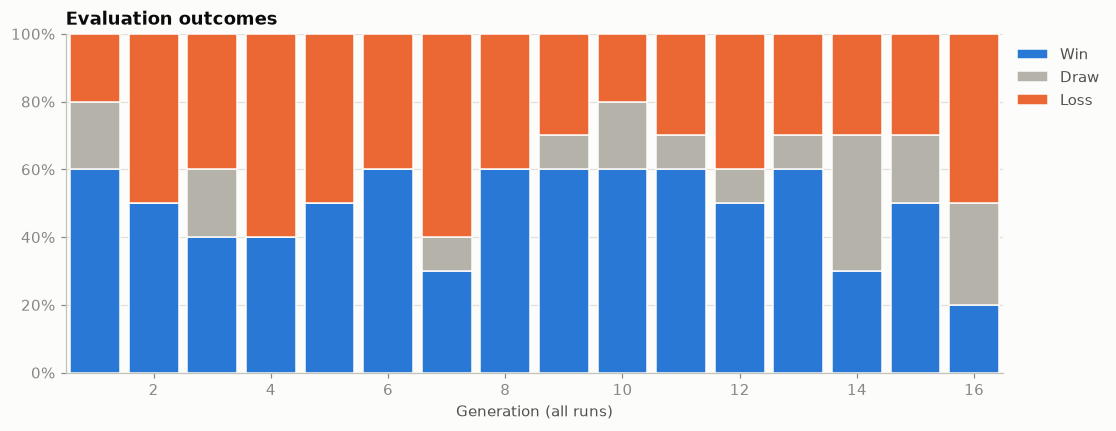

In [18]:
fig, ax = plt.subplots()
bottom = pd.Series(0.0, index=log.index)
for column, color, label in [("eval_wins", BLUE, "Win"), ("eval_draws", NEUTRAL, "Draw"), ("eval_losses", ORANGE, "Loss")]:
    share = log[column] / log.eval_games
    ax.bar(log.step, share, bottom=bottom, width=0.85, color=color, edgecolor="#fcfcfb", linewidth=1, label=label)
    bottom += share
percent_axis(ax)
ax.set_ylim(0, 1)
mark_runs(ax)
ax.set_title("Evaluation outcomes")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## Training loss

Each loss is drawn against the lowest value it could reach on that generation's data:

- **Policy:** cross-entropy can't drop below the entropy of the MCTS visit-count
  targets. The gap between the two lines is what the network still has to learn;
  a flat gap means the policy head has stopped improving.
- **Value:** the dashed line is the loss from always predicting 0. A value loss near
  it means the network can't yet tell winning positions from losing ones.

Both references move when the self-play data changes, so read the gap, not the raw loss.
The orange line is the loss on each generation's new self-play positions, measured
before the network trains on them. If it sits well above the training loss and the
gap grows, the network is memorising the replay buffer rather than generalising.

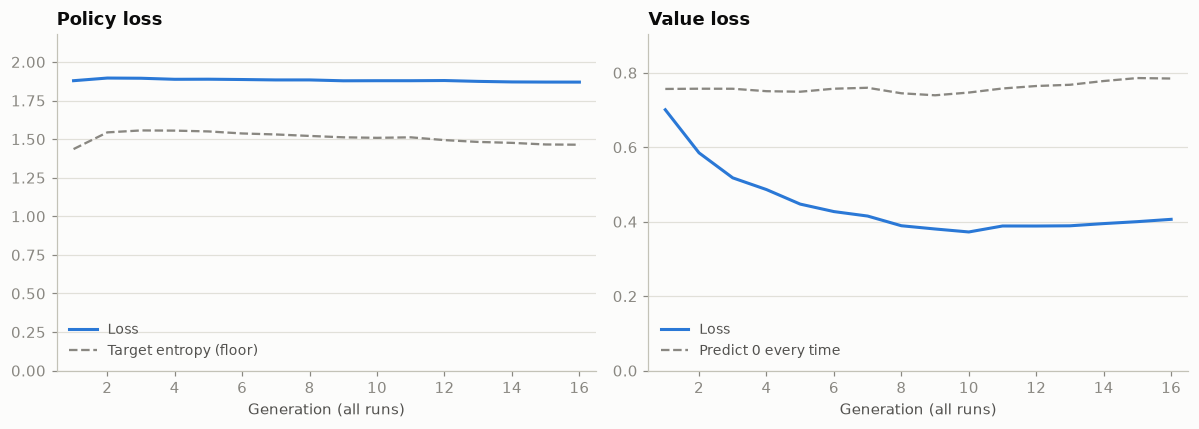

In [19]:
fig, (policy_ax, value_ax) = plt.subplots(1, 2, figsize=(11, 4))
for ax, loss, floor, floor_label, title in [
        (policy_ax, "policy_loss", "policy_target_entropy", "Target entropy (floor)", "Policy loss"),
        (value_ax, "value_loss", "value_target_mse", "Predict 0 every time", "Value loss")]:
    ax.plot(log.step, log[loss], color=BLUE, label="Training loss")
    # Newer runs also log the loss on each generation's self-play before training on
    # it. Above the training loss and rising means the network is memorising the buffer
    if f"fresh_{loss}" in log:
        ax.plot(log.step, log[f"fresh_{loss}"], color=ORANGE, label="On new positions, before training")
    ax.plot(log.step, log[floor], color=MUTED, linestyle="--", linewidth=1.5, label=floor_label)
    ax.set_ylim(0, log[[c for c in (loss, floor, f"fresh_{loss}") if c in log]].max().max() * 1.15)
    mark_runs(ax)
    ax.set_title(title)
    ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

## Self-play games

Who wins the games the network plays against itself, and how long they last. Self-play
results that lean heavily to one side, or games that get much shorter, can mean the
search has collapsed onto one line of play.

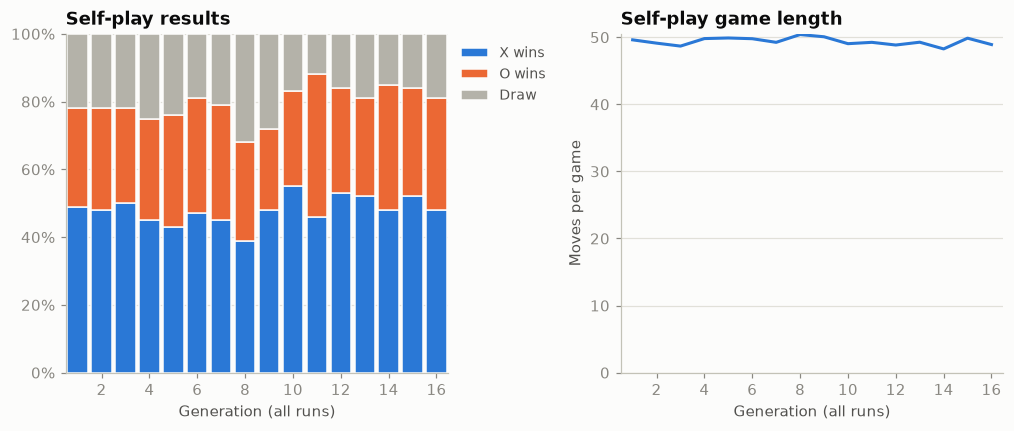

In [20]:
fig, (result_ax, length_ax) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"wspace": 0.45})
bottom = pd.Series(0.0, index=log.index)
for column, color, label in [("selfplay_x_wins", BLUE, "X wins"), ("selfplay_o_wins", ORANGE, "O wins"),
                             ("selfplay_draws", NEUTRAL, "Draw")]:
    share = log[column] / log.selfplay_games
    result_ax.bar(log.step, share, bottom=bottom, width=0.85, color=color, edgecolor="#fcfcfb", linewidth=1, label=label)
    bottom += share
percent_axis(result_ax)
result_ax.set_ylim(0, 1)
mark_runs(result_ax)
result_ax.set_title("Self-play results")
result_ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=9)

length_ax.plot(log.step, log.game_length, color=BLUE)
length_ax.set_ylim(bottom=0)
mark_runs(length_ax)
length_ax.set_ylabel("Moves per game")
length_ax.set_title("Self-play game length")
plt.show()

## Time per generation

Where each generation's time goes. Training time grows until the replay buffer is
full, because the number of batches scales with the buffer.

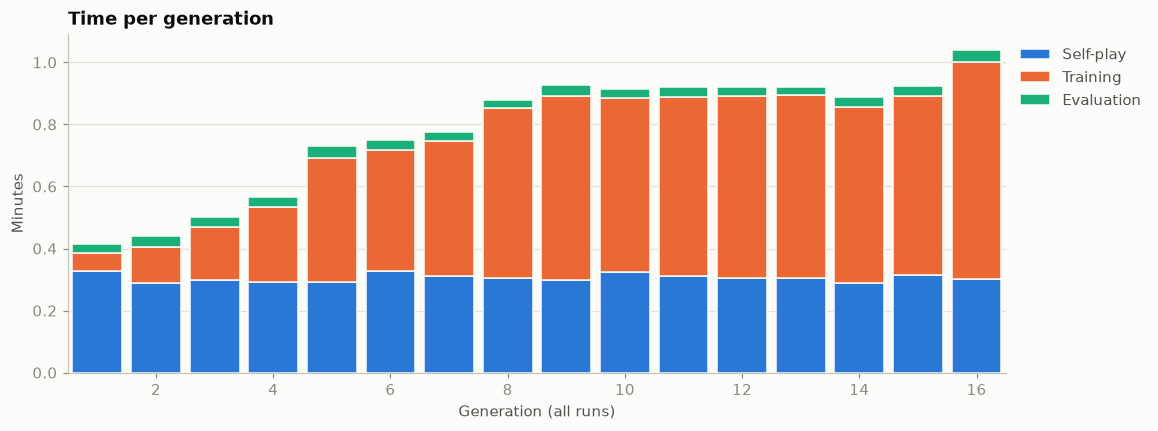

In [21]:
fig, ax = plt.subplots()
bottom = pd.Series(0.0, index=log.index)
for column, color, label in [("selfplay_seconds", BLUE, "Self-play"), ("train_seconds", ORANGE, "Training"),
                             ("eval_seconds", AQUA, "Evaluation")]:
    minutes = log[column] / 60
    ax.bar(log.step, minutes, bottom=bottom, width=0.85, color=color, edgecolor="#fcfcfb", linewidth=1, label=label)
    bottom += minutes
mark_runs(ax)
ax.set_ylabel("Minutes")
ax.set_title("Time per generation")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## Latest generations

In [22]:
recent = log.tail(10).assign(
    eval=lambda d: d.eval_wins.astype(str) + "-" + d.eval_draws.astype(str) + "-" + d.eval_losses.astype(str),
    policy_gap=lambda d: d.policy_loss - d.policy_target_entropy,
    minutes=lambda d: d.generation_seconds / 60,
)
recent[["step", "run", "generation", "eval", "win_rate_rolling", "policy_loss", "policy_gap", "value_loss",
        "value_target_mse", "game_length", "buffer_positions", "batches", "minutes"]].round(3).set_index("step")

,run,generation,eval,win_rate_rolling,policy_loss,policy_gap,value_loss,value_target_mse,game_length,buffer_positions,batches,minutes
step,,,,,,,,,,,,
7,2026-11-02 11:27:47,7,3-1-6,0.44,1.883,0.353,0.415,0.760,49.24,34612,339,0.777
8,2026-11-02 11:27:47,8,6-0-4,0.48,1.883,0.363,0.389,0.745,50.40,39652,388,0.879
9,2026-11-02 11:27:47,9,6-1-3,0.52,1.878,0.366,0.380,0.739,50.07,44659,437,0.927
10,2026-11-02 11:27:47,10,6-2-2,0.54,1.878,0.370,0.372,0.747,49.04,49563,485,0.916
11,2026-11-02 11:27:47,11,6-1-3,0.54,1.878,0.367,0.388,0.758,49.24,49526,484,0.921
12,2026-11-02 11:27:47,12,5-1-4,0.58,1.880,0.386,0.388,0.764,48.84,49498,484,0.922
13,2026-11-02 11:27:47,13,6-1-3,0.58,1.874,0.392,0.389,0.768,49.26,49556,484,0.922
14,2026-11-02 11:27:47,14,3-4-3,0.52,1.870,0.395,0.395,0.778,48.26,49402,483,0.887
15,2026-11-02 11:27:47,15,5-2-3,0.50,1.870,0.404,0.400,0.786,49.86,49399,483,0.924
